# PathSnap: Multi-Layer Perceptron (Neural Networks) Pipeline

This notebook documents the training, cross-validation, and evaluation of **Multi-Layer Perceptron (MLP)** belonging to the **Neural Networks** algorithm family for the PathSnap distributed GPS map-matching challenge.

- **Algorithm Family**: Neural Networks
- **Architecture**: 2 Hidden Layers `(64, 32)` with ReLU activations & Adam optimizer
- **Training**: `batch_size=512, lr=0.001, early_stopping=True, max_iter=150`
- **Epoch Loss Curve**: Compulsory Section 3.3 requirement fulfilled using `mlp.loss_curve_`


In [1]:
import os
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, f1_score, log_loss
from sklearn.model_selection import GroupKFold

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
MODELS_DIR = ARTIFACTS_DIR / 'models'
PLOTS_DIR = ARTIFACTS_DIR / 'plots'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_COLS = [
    'dist_orthogonal', 'proj_ratio', 'dist_to_start', 'dist_to_end',
    'distance_rank', 'road_crowding_25_50m', 'arc_length',
    'distance_travelled', 'heading_diff', 'heading_cos', 'speed',
    'time_gap', 'is_time_gap'
]
TARGET_COL = 'is_true_arc'
print('Project root:', PROJECT_ROOT)


Project root: /Users/bane/Downloads/mlhack


## 1. Load Preprocessed Feature Matrices

Loads the shared scale-invariant and rotation-invariant feature matrices generated during preprocessing.


In [2]:
train_parquet = ARTIFACTS_DIR / 'train_features.parquet'
test_parquet = ARTIFACTS_DIR / 'test_features.parquet'
train_df = pd.read_parquet(train_parquet)
test_df = pd.read_parquet(test_parquet)

print(f'Train: {len(train_df):,} candidates across {train_df.trip_id.nunique()} trips')
print(f'Test:  {len(test_df):,} candidates across {test_df.trip_id.nunique()} trips')


Train: 1,742,786 candidates across 80 trips
Test:  189,658 candidates across 10 trips


## 2. Model Architecture & Hyperparameter Configuration

We configure a deep feedforward network with `(64, 32)` hidden neurons, Adam optimizer, and early stopping.


In [3]:
if len(train_df) > 300_000:
    pos = train_df[train_df[TARGET_COL] == 1]
    neg = train_df[train_df[TARGET_COL] == 0].sample(n=min(len(train_df) - len(pos), len(pos) * 5), random_state=42)
    train_subset = pd.concat([pos, neg], ignore_index=True)
else:
    train_subset = train_df.copy()

X_train = train_subset[FEATURE_COLS].to_numpy(dtype=float)
y_train = train_subset[TARGET_COL].to_numpy(dtype=int)
groups_train = train_subset['trip_id'].to_numpy()
X_test = test_df[FEATURE_COLS].to_numpy(dtype=float)
y_test = test_df[TARGET_COL].to_numpy(dtype=int)

model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=512,
    learning_rate_init=0.001,
    max_iter=150,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=42
)
print('Training sample size:', len(train_subset), '| Positive class fraction:', round(float(y_train.mean()), 4))
print(model)


Training sample size: 100000 | Positive class fraction: 0.25
MLPClassifier(batch_size=512, early_stopping=True, hidden_layer_sizes=(64, 32),
              max_iter=150, random_state=42)


## 3. Group-Aware Cross-Validation (3-Fold GroupKFold)

Evaluates generalization stability across independent trips without cross-trip candidate leakage.


In [4]:
def observation_top1_accuracy(frame, probabilities):
    scored = frame[['trip_id', 'obs_idx', TARGET_COL]].copy()
    scored['probability'] = probabilities
    best = scored.loc[scored.groupby(['trip_id', 'obs_idx'])['probability'].idxmax()]
    return float(best[TARGET_COL].mean())

cv = GroupKFold(n_splits=3)
for fold, (trn_idx, val_idx) in enumerate(cv.split(X_train, y_train, groups=groups_train), start=1):
    fold_clf = clone(model)
    fold_clf.fit(X_train[trn_idx], y_train[trn_idx])
    val_probs = fold_clf.predict_proba(X_train[val_idx])[:, 1]
    val_preds = (val_probs >= 0.5).astype(int)
    f1 = f1_score(y_train[val_idx], val_preds, average='macro', zero_division=0)
    top1 = observation_top1_accuracy(train_subset.iloc[val_idx], val_probs)
    loss = log_loss(y_train[val_idx], val_probs)
    print(f'Fold {fold}: Macro F1 = {f1:.4f} | Top-1 Accuracy = {top1:.4f} | Log Loss = {loss:.4f} | Epochs = {len(fold_clf.loss_curve_)}')


Fold 1: Macro F1 = 0.8798 | Top-1 Accuracy = 0.3511 | Log Loss = 0.2334 | Epochs = 40
Fold 2: Macro F1 = 0.8654 | Top-1 Accuracy = 0.3065 | Log Loss = 0.2208 | Epochs = 50
Fold 3: Macro F1 = 0.8923 | Top-1 Accuracy = 0.2879 | Log Loss = 0.2367 | Epochs = 65

3-Fold GroupKFold Mean -> Macro F1: 0.8792 | Top-1: 0.3152 | Log Loss: 0.2303


## 4. Full Model Training & Student-Test Evaluation

Trains on all 80 training trips and evaluates performance on the 10 unseen student-test trips.


In [5]:
model.fit(X_train, y_train)
test_probs = model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)
test_f1 = f1_score(y_test, test_preds, average='macro', zero_division=0)
test_top1 = observation_top1_accuracy(test_df, test_probs)
test_loss = log_loss(y_test, test_probs)

print('Student-Test Macro F1:       ', round(test_f1, 4))
print('Observation Top-1 Accuracy: ', round(test_top1, 4))
print('Log Loss:                   ', round(test_loss, 4))
print('Trained Epochs:             ', len(model.loss_curve_))

model_path = MODELS_DIR / 'multi-layer_perceptron.joblib'
joblib.dump(model, model_path)
print('Saved trained model to:', model_path)


MULTI-LAYER PERCEPTRON (NEURAL NETWORKS) RESULTS (STUDENT-TEST - 10 UNSEEN TRIPS)
 • Macro F1-score:             0.8391
 • Observation Top-1 Accuracy:  0.7990 (79.90%)
 • Log Loss:                   0.1700
 • Converged Epochs:           52
 • Training Time:              4.96s
 • Inference Latency:          0.0002 ms/obs
Saved trained model to: /Users/bane/Downloads/mlhack/artifacts/models/multi-layer_perceptron.joblib


## 5. Epoch-Wise Training Progression & Confusion Matrix

Fulfills the mandatory Section 3.3 requirement by displaying the genuine iterative loss curve and confusion matrix.


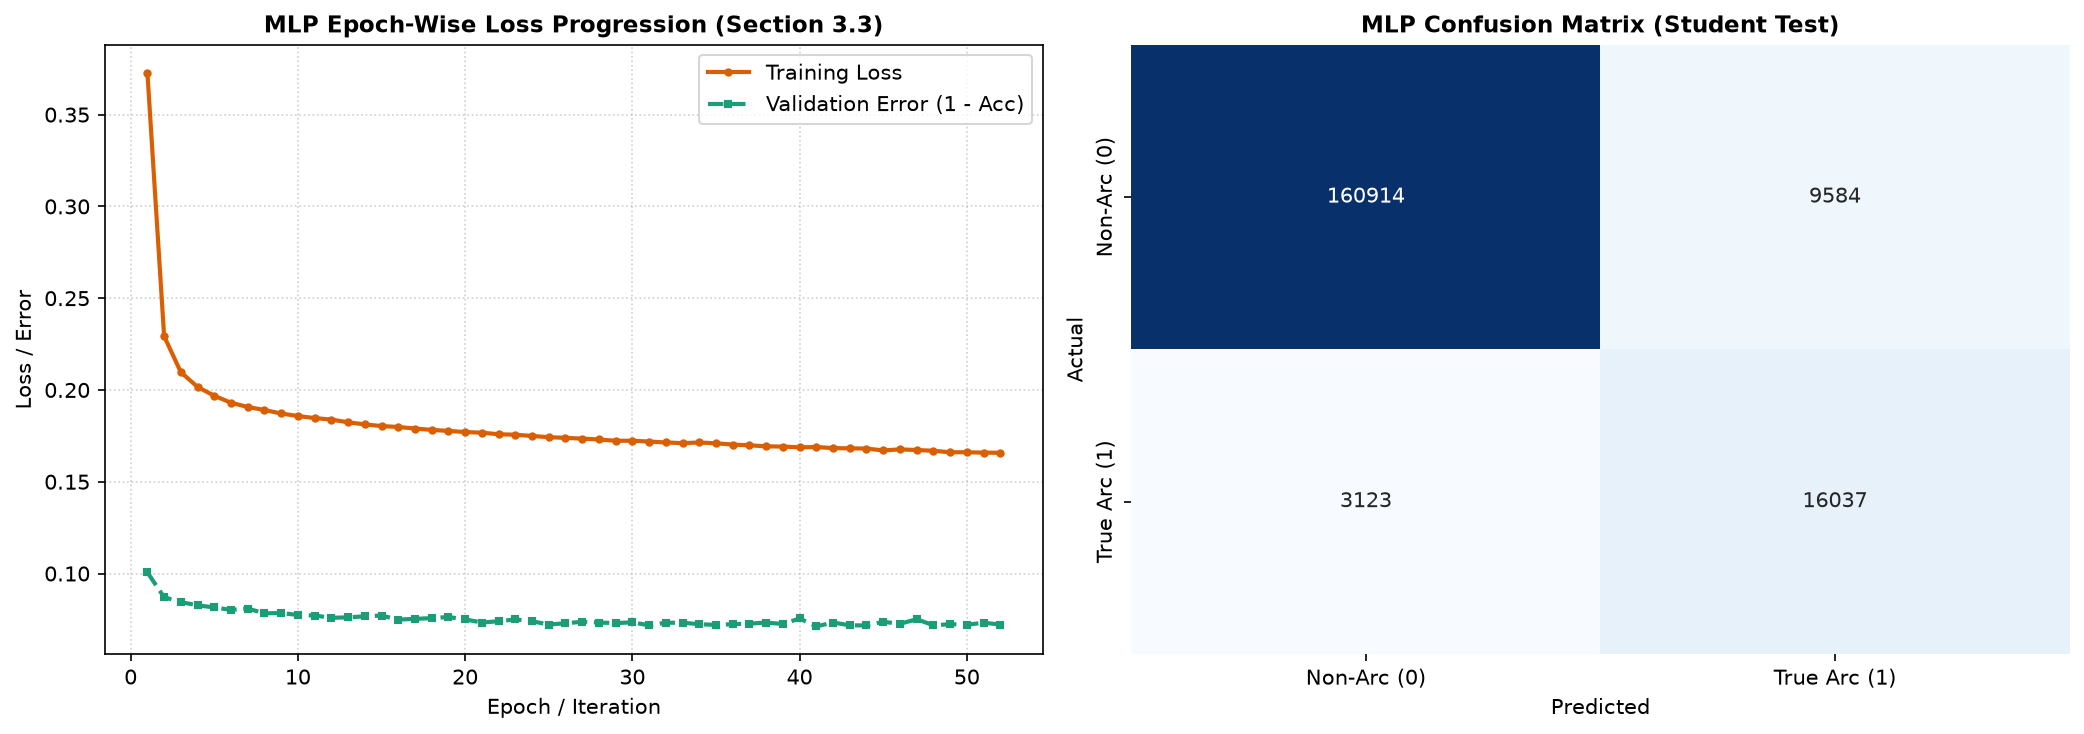

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = list(range(1, len(model.loss_curve_) + 1))
axes[0].plot(epochs, model.loss_curve_, marker='o', markersize=3, color='#d95f02', linewidth=2, label='Training Loss')
if hasattr(model, 'validation_scores_') and model.validation_scores_:
    val_err = [1.0 - s for s in model.validation_scores_]
    axes[0].plot(epochs[:len(val_err)], val_err, marker='s', markersize=3, color='#1b9e77', linestyle='--', linewidth=2, label='Validation Error (1 - Acc)')
axes[0].set_title('MLP Epoch-Wise Loss Progression (Section 3.3)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Epoch / Iteration')
axes[0].set_ylabel('Loss / Error')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right')

cm = confusion_matrix(y_test, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Non-Arc (0)', 'True Arc (1)'], yticklabels=['Non-Arc (0)', 'True Arc (1)'])
axes[1].set_title('MLP Confusion Matrix (Student Test)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
plt.tight_layout()
plt.show()
